# Primeiro agente PPO: treinamento geracional

Este notebook treina uma política PPO compartilhada em partidas de quatro jogadores. Em cada partida, um assento é controlado pela rede e os demais pela liga (Random, Aggressive, Conservative e, nas gerações seguintes, snapshots históricos). O banco salva uma política congelada ao fim de cada geração.

O experimento padrão abaixo usa **5 gerações de 20 partidas** e avalia cada snapshot contra os três perfis heurísticos. Esses números são um piloto visual; aumente partidas por geração para conclusões mais confiáveis. A avaliação por geração também é pequena e exploratória.

In [5]:
from datetime import datetime
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd()
if not (ROOT / 'app').exists() and (ROOT.parent / 'app').exists():
    ROOT = ROOT.parent
assert (ROOT / 'app').exists(), 'Abra o notebook na raiz do repositório.'
sys.path.insert(0, str(ROOT))
print(f'Repositório: {ROOT}')

Repositório: /media/marth/Dados/Arquivos/Monopoly-AI


## Mapa da rede

O ator compartilha os pesos para todos os tipos de ação. Para trocas, o tipo da ação e a oferta são codificados junto das consequências condicionais calculadas pelo analytics. A cabeça do crítico estima o valor do estado; ela não escolhe a ação.

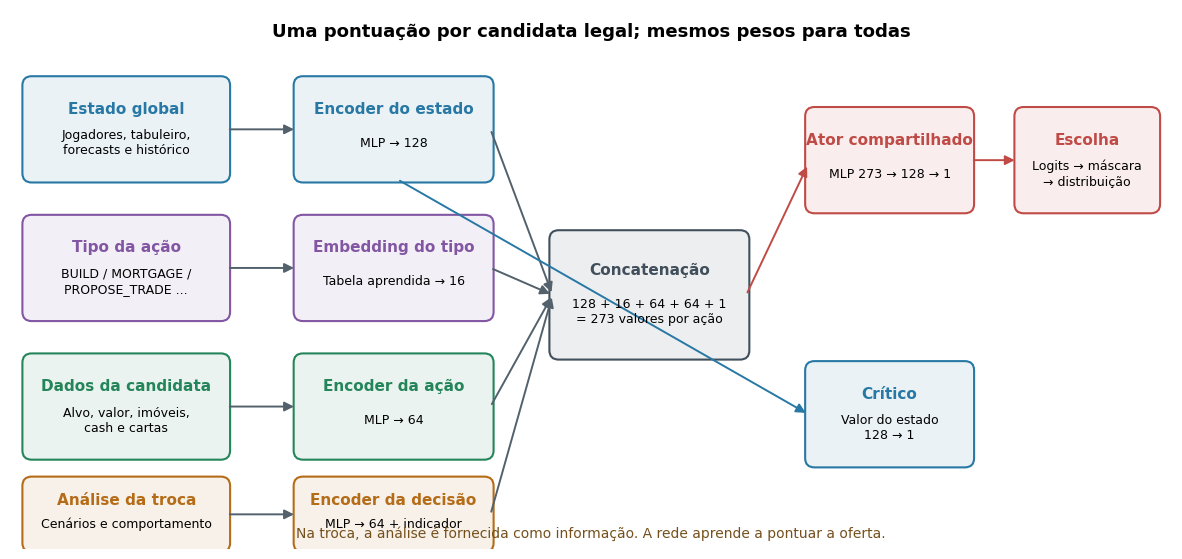

In [6]:
def draw_network():
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 7)
    ax.axis('off')

    def box(x, y, w, h, title, body, color):
        patch = FancyBboxPatch(
            (x, y), w, h,
            boxstyle='round,pad=0.04,rounding_size=0.12',
            linewidth=1.5,
            edgecolor=color,
            facecolor=color + '18',
        )
        ax.add_patch(patch)
        ax.text(x + w / 2, y + h * 0.70, title, ha='center', va='center',
                fontsize=11, weight='bold', color=color)
        ax.text(x + w / 2, y + h * 0.36, body, ha='center', va='center',
                fontsize=9, wrap=True)

    def arrow(x1, y1, x2, y2, color='#52616b'):
        ax.add_patch(FancyArrowPatch(
            (x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=14,
            linewidth=1.4, color=color,
        ))

    box(.2, 4.8, 2.6, 1.3, 'Estado global',
        'Jogadores, tabuleiro,\nforecasts e histórico', '#2878a5')
    box(.2, 3.0, 2.6, 1.3, 'Tipo da ação',
        'BUILD / MORTGAGE /\nPROPOSE_TRADE ...', '#8256a3')
    box(.2, 1.2, 2.6, 1.3, 'Dados da candidata',
        'Alvo, valor, imóveis,\ncash e cartas', '#25855a')
    box(.2, .0, 2.6, .9, 'Análise da troca',
        'Cenários e comportamento', '#b56c18')

    box(3.7, 4.8, 2.5, 1.3, 'Encoder do estado', 'MLP → 128', '#2878a5')
    box(3.7, 3.0, 2.5, 1.3, 'Embedding do tipo',
        'Tabela aprendida → 16', '#8256a3')
    box(3.7, 1.2, 2.5, 1.3, 'Encoder da ação', 'MLP → 64', '#25855a')
    box(3.7, .0, 2.5, .9, 'Encoder da decisão',
        'MLP → 64 + indicador', '#b56c18')

    for y in (5.45, 3.65, 1.85, .45):
        arrow(2.8, y, 3.7, y)

    box(7.0, 2.5, 2.5, 1.6, 'Concatenação',
        '128 + 16 + 64 + 64 + 1\n= 273 valores por ação', '#404f5b')
    for y in (5.45, 3.65, 1.85, .45):
        arrow(6.2, y, 7.0, 3.3)

    box(10.3, 4.4, 2.1, 1.3, 'Ator compartilhado',
        'MLP 273 → 128 → 1', '#c04b46')
    box(10.3, 1.1, 2.1, 1.3, 'Crítico',
        'Valor do estado\n128 → 1', '#2878a5')
    arrow(9.5, 3.3, 10.3, 5.0, '#c04b46')
    arrow(5.0, 4.8, 10.3, 1.75, '#2878a5')

    box(13.0, 4.4, 1.8, 1.3, 'Escolha',
        'Logits → máscara\n→ distribuição', '#c04b46')
    arrow(12.4, 5.05, 13.0, 5.05, '#c04b46')
    ax.text(7.5, 6.65,
            'Uma pontuação por candidata legal; mesmos pesos para todas',
            ha='center', fontsize=13, weight='bold')
    ax.text(7.5, .15,
            'Na troca, a análise é fornecida como informação. A rede aprende a pontuar a oferta.',
            ha='center', fontsize=10, color='#75501d')
    plt.show()

draw_network()


## Configuração do piloto

`GAMES_PER_GENERATION` controla o tamanho de cada geração; `NUM_GENERATIONS` define quantos snapshots serão treinados. Por exemplo, 5 gerações de 20 partidas significam 100 partidas de treino. O ambiente reserva capacidade de observação para até 12 jogadores, embora este primeiro experimento use quatro. `NUM_WORKERS` distribui partidas pela CPU; `DEVICE = 'auto'` usa CUDA na atualização da rede quando disponível. As partidas continuam sendo simuladas na CPU.

Para retomar após uma interrupção, defina `RESUME_FROM` no próximo bloco como o caminho de `ppo_latest.pt`. Se só houver um snapshot antigo, use `policy_bank/generation_XXXXX.pt`; nesse caso os pesos são recuperados, mas o otimizador e o histórico anterior não.

In [7]:
NUM_PLAYERS = 4
NUM_WORKERS = 8
DEVICE = 'auto'
NUM_GENERATIONS = 5
GAMES_PER_GENERATION = 20
SEED = 2026
MAX_TURNS = 3000
EVAL_GAMES_PER_OPPONENT = 3
# Se o treino for interrompido, informe o caminho ppo_latest.pt para retomar.
RESUME_FROM = None  # Ex.: Path('/.../runs/first_agent/<run>/checkpoints/ppo_latest.pt')
if RESUME_FROM is None:
    RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
    RUN_DIR = ROOT / 'runs' / 'first_agent' / RUN_ID
    BANK_DIR = RUN_DIR / 'policy_bank'
    CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
else:
    RESUME_FROM = Path(RESUME_FROM)
    if RESUME_FROM.parent.name == 'policy_bank':
        # Warm-start from a generation snapshot saved by an older run.
        BANK_DIR = RESUME_FROM.parent
        RUN_DIR = BANK_DIR.parent
        CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
    else:
        CHECKPOINT_DIR = RESUME_FROM.parent
        RUN_DIR = CHECKPOINT_DIR.parent
        BANK_DIR = RUN_DIR / 'policy_bank'
    RUN_ID = RUN_DIR.name
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f'Jogadores: {NUM_PLAYERS} | workers CPU: {NUM_WORKERS} | dispositivo da rede: {DEVICE}')
print(f'Gerações: {NUM_GENERATIONS} × {GAMES_PER_GENERATION} = {NUM_GENERATIONS * GAMES_PER_GENERATION} partidas')
print(f'Avaliação: {NUM_GENERATIONS} snapshots × 3 oponentes × {EVAL_GAMES_PER_OPPONENT} partidas')
print(f'Banco: {BANK_DIR}')
STATUS_DIR = BANK_DIR / 'episode_status'
print(f'Status detalhado das partidas: {STATUS_DIR}')
print(f'Retomando de: {RESUME_FROM}' if RESUME_FROM else 'Novo treino')

Jogadores: 4 | workers CPU: 8 | dispositivo da rede: auto
Gerações: 5 × 20 = 100 partidas
Avaliação: 5 snapshots × 3 oponentes × 3 partidas
Banco: /media/marth/Dados/Arquivos/Monopoly-AI/runs/first_agent/20261105_173809/policy_bank


## Treino

As features condicionais de troca estão ativadas. Para cada oferta candidata, o analytics calcula cenários de aceitação e recusa, efeitos e previsões para ambos os participantes, além do perfil histórico do oponente. O cálculo acrescenta custo por decisão de troca. A política é atualizada a cada oito partidas (e no fechamento da geração) e um snapshot é salvo no banco ao fim de cada geração.

In [8]:
import sys
sys.path.insert(0, str(ROOT))
from app.training import PPOTrainingConfig, train_ppo

config = PPOTrainingConfig(
    episodes=NUM_GENERATIONS * GAMES_PER_GENERATION,
    seed=SEED,
    num_players=NUM_PLAYERS,
    max_turns=MAX_TURNS,
    max_candidates=128,
    episodes_per_update=8,
    generation_size=GAMES_PER_GENERATION,
    archive_opponent_rate=0.5,
    archive_dir=str(BANK_DIR),
    evaluation_interval=0,
    trade_analysis_mode='automatic',
    num_workers=NUM_WORKERS,
    device=DEVICE,
)

def progress(event):
    if event['event'] == 'episode_start':
        episode = int(event['episode'])
        if episode == 1 or episode % 5 == 0:
            print(f"Iniciando partida {episode}/{config.episodes}; geração {int(event['generation'])}; oponentes={event['opponents']}", flush=True)
        return
    print(
        f"Fim {int(event['episode'])}/{config.episodes} | retorno={event['return']:+.0f} | "
        f"vitória={int(event['win'])} | falência={int(event['bankrupt'])} | "
        f"truncada={int(event['truncated'])} | turnos={int(event['turns'])}",
        flush=True,
    )

agent, history = train_ppo(
    config,
    league=None,  # TrainingLeague padrão; substitua por uma liga customizada quando quiser
    checkpoint_path=CHECKPOINT_DIR / 'ppo_latest.pt',
    resume_from=RESUME_FROM,
    progress_callback=progress,
)
history_df = pd.DataFrame(history)
history_df['generation'] = ((history_df['episode'] - 1) // GAMES_PER_GENERATION) + 1
history_path = RUN_DIR / 'training_history.csv'
history_df.to_csv(history_path, index=False)
print(f'Histórico salvo em: {history_path}')

Iniciando partida 1/100; geração 1; oponentes=('conservative', 'aggressive', 'random')
Iniciando partida 5/100; geração 1; oponentes=('random', 'conservative', 'aggressive')


Exception in initializer:
Traceback (most recent call last):
  File "/home/marth/anaconda3/envs/dev_ambient/lib/python3.13/concurrent/futures/process.py", line 233, in _process_worker
    initializer(*initargs)
    ~~~~~~~~~~~^^^^^^^^^^^
  File "/media/marth/Dados/Arquivos/Monopoly-AI/app/training/ppo.py", line 382, in _initialize_rollout_worker
    _ROLLOUT_WORKER_AGENT = _CandidatePPO(_ROLLOUT_WORKER_ENV, worker_config)
  File "/media/marth/Dados/Arquivos/Monopoly-AI/app/training/ppo.py", line 225, in __init__
    self.optimizer = torch.optim.Adam(self.network.parameters(), lr=config.learning_rate)
                     ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/marth/anaconda3/envs/dev_ambient/lib/python3.13/site-packages/torch/optim/adam.py", line 102, in __init__
    super().__init__(params, defaults)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/home/marth/anaconda3/envs/dev_ambient/lib/python3.13/site-packages/torch/optim/optimizer.py", l

KeyboardInterrupt: 

## Evolução dentro e entre gerações

As curvas de vitórias e recompensas por episódio são ruidosas. As médias por geração ajudam a acompanhar a tendência, mas 20 partidas por geração ainda são uma amostra piloto. Truncagens permanecem separadas de vitórias e derrotas.

In [ ]:
rolling_window = min(20, len(history_df))
rolling = history_df.set_index('episode')[['win','return','truncated']].rolling(rolling_window, min_periods=1).mean()
gen_summary = history_df.groupby('generation').agg(
    games=('episode','count'),
    win_rate=('win','mean'),
    bankruptcy_rate=('bankrupt','mean'),
    truncation_rate=('truncated','mean'),
    mean_return=('return','mean'),
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rolling['win'].plot(ax=axes[0,0], color='seagreen', title=f'Taxa de vitórias móvel ({rolling_window} partidas)')
rolling['return'].plot(ax=axes[0,1], color='royalblue', title='Retorno médio móvel')
axes[1,0].plot(gen_summary['generation'], gen_summary['win_rate'], marker='o', label='Vitórias')
axes[1,0].plot(gen_summary['generation'], gen_summary['bankruptcy_rate'], marker='o', label='Falências')
axes[1,0].plot(gen_summary['generation'], gen_summary['truncation_rate'], marker='o', label='Truncagens')
axes[1,0].set(title='Resultados por geração', xlabel='Geração', ylabel='Fração', ylim=(0,1)); axes[1,0].legend()
losses = history_df.dropna(subset=['policy_loss','value_loss'])
if not losses.empty:
    axes[1,1].plot(losses['episode'], losses['policy_loss'], marker='.', label='Policy loss')
    axes[1,1].plot(losses['episode'], losses['value_loss'], marker='.', label='Value loss')
    axes[1,1].set(title='Perdas PPO nos updates', xlabel='Partida', ylabel='Perda'); axes[1,1].legend()
else:
    axes[1,1].text(.5,.5,'Ainda não há updates registrados',ha='center',va='center',transform=axes[1,1].transAxes)
for ax in axes.flat: ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
display(gen_summary)

## Oponentes enfrentados por geração

O manifesto registra quantas partidas cada snapshot enfrentou contra cada heurística e quais gerações arquivadas apareceram como oponentes. A política PPO começa contra as três heurísticas; depois, o banco introduz snapshots anteriores.

In [ ]:
manifest = json.loads((BANK_DIR / 'manifest.json').read_text(encoding='utf-8'))
exposure_rows = []
for policy in manifest['policies']:
    exposure = policy['opponent_exposure']
    row = {'generation': policy['generation'], **{k:v for k,v in exposure.items() if k != 'archive_generations'}}
    row['archive_generations'] = sum(exposure.get('archive_generations', {}).values())
    exposure_rows.append(row)
exposure_df = pd.DataFrame(exposure_rows).fillna(0).sort_values('generation')
exposure_df = exposure_df.set_index('generation')
exposure_df[['random','aggressive','conservative','archive']].plot(kind='bar', stacked=True, figsize=(11,5), colormap='tab20')
plt.ylabel('Assentos oponentes observados'); plt.title('Exposição acumulada em cada geração'); plt.grid(axis='y',alpha=.25); plt.show()
display(exposure_df)

## Avaliação de cada snapshot

Cada geração é avaliada contra três cópias de uma heurística em partidas de quatro jogadores. A mesma faixa de seeds é reutilizada para comparar gerações e o assento do agente é rotacionado. O número pequeno de partidas é apenas exploratório; aumente `EVAL_GAMES_PER_OPPONENT` para a avaliação formal.

In [ ]:
from app.training.ppo import evaluate_ppo_matchups, load_ppo_checkpoint

EVAL_OPPONENTS = ('random','aggressive','conservative')
EVAL_SEED = SEED + 200_000
eval_rows = []
for entry in manifest['policies']:
    snapshot_path = BANK_DIR / entry['path']
    print(f"Avaliando geração {entry['generation']}...", flush=True)
    snapshot_agent, snapshot_config = load_ppo_checkpoint(snapshot_path)
    rows = evaluate_ppo_matchups(
        snapshot_agent, snapshot_config, opponents=EVAL_OPPONENTS,
        games=EVAL_GAMES_PER_OPPONENT, seed=EVAL_SEED,
    )
    for row in rows:
        row['generation'] = entry['generation']
    eval_rows.extend(rows)
    del snapshot_agent
eval_df = pd.DataFrame(eval_rows)
eval_path = RUN_DIR / 'generation_evaluation.csv'
eval_df.to_csv(eval_path, index=False)
eval_summary = eval_df.groupby(['generation','opponent']).agg(
    games=('win','count'), win_rate=('win','mean'),
    bankruptcy_rate=('bankrupt','mean'), truncation_rate=('truncated','mean'),
    mean_turns=('turns','mean'),
).reset_index()
print(f'Resultados por partida: {eval_path}')
display(eval_summary)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for opponent, group in eval_summary.groupby('opponent'):
    axes[0].plot(group['generation'], group['win_rate'], marker='o', label=opponent)
    axes[1].plot(group['generation'], group['truncation_rate'], marker='o', label=opponent)
axes[0].set(title='Vitórias por geração e oponente', xlabel='Geração', ylabel='Taxa de vitória', ylim=(0,1))
axes[1].set(title='Truncagens por geração e oponente', xlabel='Geração', ylabel='Taxa de truncagem', ylim=(0,1))
for ax in axes: ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.show()

## Próximo orçamento de treino

Após observar o piloto, aumente `GAMES_PER_GENERATION` para 100 ou mais e `NUM_GENERATIONS` conforme o tempo disponível. Um banco maior diversifica os oponentes, mas não garante por si só ausência de overfitting: mantenha seeds de avaliação separados e compare cada perfil individualmente. O treino atual usa resultado terminal (+1/−1/0); não atribui recompensa intermediária a patrimônio nem à aceitação de uma troca.